Importing Dependencies

In [2]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
RANDOM_STATE = 42

In [3]:
sonar_data = pd.read_csv('sonar_data.csv', header = None)

In [4]:
sonar_data.head()

,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [8]:
sonar_data.shape

(208, 61)

In [9]:
sonar_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       208 non-null    float64
 1   1       208 non-null    float64
 2   2       208 non-null    float64
 3   3       208 non-null    float64
 4   4       208 non-null    float64
 5   5       208 non-null    float64
 6   6       208 non-null    float64
 7   7       208 non-null    float64
 8   8       208 non-null    float64
 9   9       208 non-null    float64
 10  10      208 non-null    float64
 11  11      208 non-null    float64
 12  12      208 non-null    float64
 13  13      208 non-null    float64
 14  14      208 non-null    float64
 15  15      208 non-null    float64
 16  16      208 non-null    float64
 17  17      208 non-null    float64
 18  18      208 non-null    float64
 19  19      208 non-null    float64
 20  20      208 non-null    float64
 21  21      208 non-null    float64
 22  22      208 n

In [10]:
sonar_data.describe()

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
count,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,...,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000
mean,0.029164,0.038437,0.043832,0.053892,0.075202,0.104570,0.121747,0.134799,0.178003,0.208259,...,0.016069,0.013420,0.010709,0.010941,0.009290,0.008222,0.007820,0.007949,0.007941,0.006507
std,0.022991,0.032960,0.038428,0.046528,0.055552,0.059105,0.061788,0.085152,0.118387,0.134416,...,0.012008,0.009634,0.007060,0.007301,0.007088,0.005736,0.005785,0.006470,0.006181,0.005031
min,0.001500,0.000600,0.001500,0.005800,0.006700,0.010200,0.003300,0.005500,0.007500,0.011300,...,0.000000,0.000800,0.000500,0.001000,0.000600,0.000400,0.000300,0.000300,0.000100,0.000600
25%,0.013350,0.016450,0.018950,0.024375,0.038050,0.067025,0.080900,0.080425,0.097025,0.111275,...,0.008425,0.007275,0.005075,0.005375,0.004150,0.004400,0.003700,0.003600,0.003675,0.003100
50%,0.022800,0.030800,0.034300,0.044050,0.062500,0.092150,0.106950,0.112100,0.152250,0.182400,...,0.013900,0.011400,0.009550,0.009300,0.007500,0.006850,0.005950,0.005800,0.006400,0.005300
75%,0.035550,0.047950,0.057950,0.064500,0.100275,0.134125,0.154000,0.169600,0.233425,0.268700,...,0.020825,0.016725,0.014900,0.014500,0.012100,0.010575,0.010425,0.010350,0.010325,0.008525
max,0.137100,0.233900,0.305900,0.426400,0.401000,0.382300,0.372900,0.459000,0.682800,0.710600,...,0.100400,0.070900,0.039000,0.035200,0.044700,0.039400,0.035500,0.044000,0.036400,0.043900


In [11]:
sonar_data[60].value_counts()

60
M    111
R     97
Name: count, dtype: int64

In [12]:
sonar_data.isnull().sum().sum()

np.int64(0)

Visualization

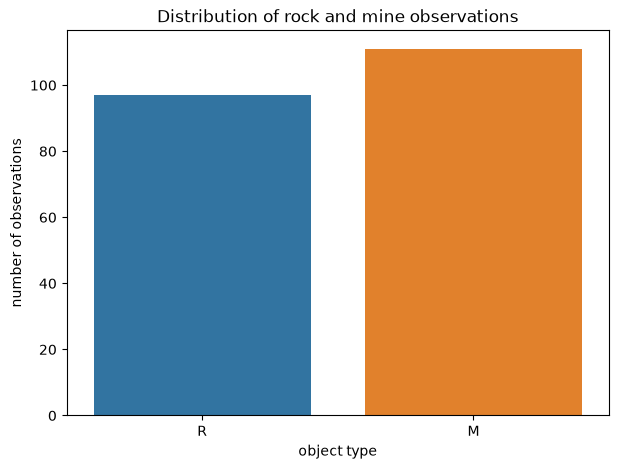

In [14]:
plt.figure(figsize=(7,5))
sns.countplot(
    x = sonar_data[60],
    hue = sonar_data[60],
    legend = False
)

plt.title("Distribution of rock and mine observations")
plt.xlabel("object type")
plt.ylabel("number of observations")

plt.show()

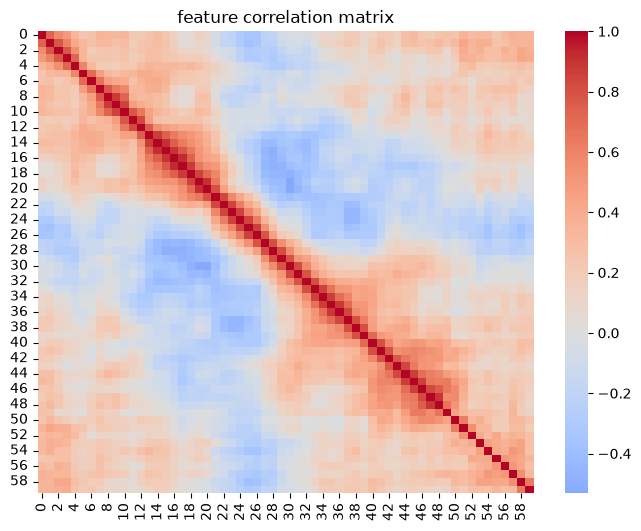

In [30]:
plt.figure(figsize=(8,6))
correlation_matrix = sonar_data.iloc[:, :60].corr()

sns.heatmap(correlation_matrix, cmap = 'coolwarm', center = 0)
plt.title("feature correlation matrix")
plt.show()

Data preprocessing

In [17]:
X = sonar_data.drop(columns = 60)
y = sonar_data[60]
print('features shape: ', X.shape)
print('target shape: ', y.shape)

features shape:  (208, 60)
target shape:  (208,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = RANDOM_STATE, stratify=y)

In [19]:
logistic_model = Pipeline([("scaler", StandardScaler()), ('classifier', LogisticRegression(max_iter = 1000, random_state = RANDOM_STATE))])

In [20]:
baseline_model = DummyClassifier(strategy = 'most_frequent')
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)
print("baseline accuracy: ", accuracy_score(y_test, baseline_predictions))

baseline accuracy:  0.5238095238095238


In [23]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter = 1000,
            random_state = RANDOM_STATE
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ('classifier', SVC(
            kernel = 'rbf',
            probability= True,
            random_state = RANDOM_STATE
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators = 200,
        random_state = RANDOM_STATE
    )
}

In [27]:
cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = RANDOM_STATE
)
scoring = {
    "accuracy" : "accuracy",
    "precision": "precision_macro",
    "recall" : "recall_macro",
    "f1": "f1_macro",
    "roc_auc": "roc_auc"
}

results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv = cv, scoring = scoring
    )
    results.append({
        "Model": name, 
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores['test_f1'].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })
results_df = pd.DataFrame(results)
results_df.sort_values(by="F1", ascending = False)

/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/p

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,SVM,0.831373,0.845731,0.825784,0.825950,0.922998
2,Random Forest,0.825312,0.835889,0.819395,0.821088,0.906836
0,Logistic Regression,0.735116,0.749036,0.733562,0.730414,0.825403


In [28]:
best_model = models["SVM"]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print(classification_report(
    y_test, y_pred, target_names = ["Mine", "Rock"]
))

              precision    recall  f1-score   support

        Mine       0.81      0.95      0.88        22
        Rock       0.94      0.75      0.83        20

    accuracy                           0.86        42
   macro avg       0.87      0.85      0.85        42
weighted avg       0.87      0.86      0.86        42



/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


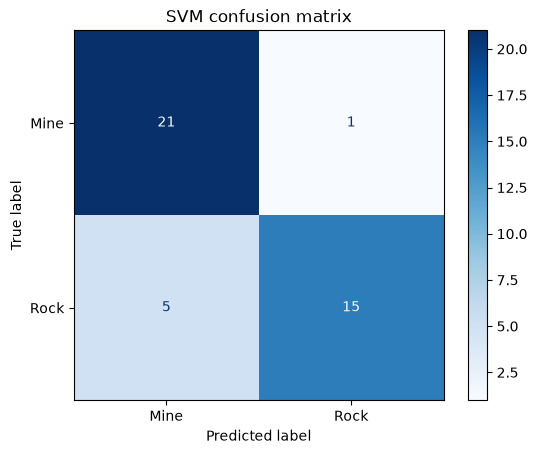

In [29]:
cm = confusion_matrix(y_test, y_pred, labels = ["M", "R"])
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = ["Mine", "Rock"])
disp.plot(cmap = "Blues")
plt.title("SVM confusion matrix")
plt.show()